In [2]:
%pip install pandas
%pip install sodapy


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [14]:
import pandas as pd
from sodapy import Socrata

# Unauthenticated client only works with public data sets. Note 'None'
# in place of application token, and no username or password:
#client = Socrata("data.transportation.gov", None)

client = Socrata( "data.transportation.gov",
                     '1hCte9vYL7IpE7pFTGR1cbn8y',
                     username="hugo.baca4515@coyote.csusb.edu",
                     password="Hugobacaalex1!")

# First 2000 results, returned as JSON from API / converted to Python list of
# dictionaries by sodapy.
results = client.get_all("byy5-w977")

# Convert to pandas DataFrame
Raw_2023 = pd.DataFrame.from_records(results)
#let's see what we get back
print(Raw_2023)


       reportingrailroadcode                 reportingrailroadname  year  \
0                         BN  Burlington Northern Railroad Company  1978   
1                         BN  Burlington Northern Railroad Company  1978   
2                         BN  Burlington Northern Railroad Company  1975   
3                         BN  Burlington Northern Railroad Company  1976   
4                         BN  Burlington Northern Railroad Company  1977   
...                      ...                                   ...   ...   
167349                    UP        Union Pacific Railroad Company  2015   
167350                    UP        Union Pacific Railroad Company  1992   
167351                    UP        Union Pacific Railroad Company  2016   
167352                    UP        Union Pacific Railroad Company  1978   
167353                    UP        Union Pacific Railroad Company  1979   

       accidentnumber                                                url  \
0          

In [4]:
from numpy.core.fromnumeric import sort

column_headers = list(Raw_2023.columns.values)

column_headers.sort()

print("The Column Headers:")
for header in column_headers:
  print(header)

The Column Headers:
:@computed_region_8fe2_rd7y
:@computed_region_m2nu_4dib
accident_type_code
accidentcause
accidentcausecode
accidentmonth
accidentnumber
accidenttype
accidentyear
adjunct_code_1
adjunct_code_2
adjunct_code_3
adjunctname1
adjunctname2
adjunctname3
brakemenonduty
cabooses
causingcarinitials
causingcarloaded
causingcarnumber
causingcarposition
class
classcode
conductorsonduty
contributingaccidentcause
contributingaccidentcausecode
countycode
countyname
date
day
derailedcabooses
derailedemptyfreightcars
derailedemptypassengercars
derailedheadendlocomotives
derailedloadedfreightcars
derailedloadedpassengercars
derailedmidtrainmanuallo
derailedmidtrainremotelo
derailedrearendmanualloc
derailedrearendremoteloc
district
division
divisioncode
emptyfreightcars
emptypassengercars
engineersonduty
equipment_type_code
equipmentattended
equipmentdamagecost
equipmenttype
firemenonduty
firstcarinitials
firstcarloaded
firstcarnumber
firstcarposition
grosstonnage
gxid
hazmatcars
hazmat

In [5]:
#i would like to break up data into smaller chunks to make it easier to work with
# such as by 10 years

print(Raw_2023['year'].max())
print(Raw_2023['year'].min())




2023
1975


In [6]:
#assuming data collection gets better as time ages, 2023 > 2022 > ...
#so we will use 2023 as the last year of data collection
Raw_2023 = Raw_2023[Raw_2023['year'] == '2023']
print(Raw_2023.head())

from tabulate import tabulate
print(tabulate(Raw_2023, headers = 'keys', tablefmt = 'psql'))


     reportingrailroadcode                             reportingrailroadname  \
102                    ALS                          Alton & Southern Railway   
631                    ARR                       Alaska Railroad Corporation   
874                    ALS                          Alton & Southern Railway   
907                    ATK  Amtrak (National Railroad Passenger Corporation)   
1173                   ALS                          Alton & Southern Railway   

      year accidentnumber                                                url  \
102   2023      0123AS020  {'url': 'https://safetydata.fra.dot.gov/Office...   
631   2023        2023111  {'url': 'https://safetydata.fra.dot.gov/Office...   
874   2023      0623AS009  {'url': 'https://safetydata.fra.dot.gov/Office...   
907   2023         174381  {'url': 'https://safetydata.fra.dot.gov/Office...   
1173  2023      0623AS002  {'url': 'https://safetydata.fra.dot.gov/Office...   

     accidentyear accidentmonth mainte

In [11]:
#Explore for NA's, missing data, and redunnacy

isnaValues = Raw_2023.isna()
print(isnaValues)

# Check for NA values
missing_values = Raw_2023.isna().sum()

#check for null values
missing_data = Raw_2023.isnull().sum()
print(missing_data)

# Check for missing data
for column in Raw_2023.columns:
    if missing_values[column] > 0:
        print(f"The column {column} has {missing_values[column]} missing values.")

# Check for redundancy
for column in Raw_2023.columns:
    if Raw_2023[column].duplicated().sum() > 0:
        print(f"The column {column} has {Raw_2023[column].duplicated().sum()} duplicate values.")

#lets try to clean up raw data

# Calculate the percentage of missing values in each column
missing_values = Raw_2023.isna().mean()

# Drop columns with more than 30% missing values
drop_list = [column for column in missing_values.index if missing_values[column] > 0.3]

# Drop the columns
Raw_2023_clean = Raw_2023.drop(columns=drop_list)


#drop empty rows
Raw_2023 = Raw_2023.dropna()

# Check the shape of the raw data
print(f"The Raw Data Frame has {Raw_2023.shape[0]} rows and {Raw_2023.shape[1]} columns.")
print(f"\n The Raw Data Frame has {len(Raw_2023.columns)} labels.")
print(f"\n The Clean Data Frame now has {len(Raw_2023_clean.columns)} labels.")
print("\n Count of labels dropped: \n", len(Raw_2023.columns) - len(Raw_2023_clean.columns) )
print("\n Deleted Labels: \n", drop_list)
print("\n Cleaned Data Labels: \n", Raw_2023_clean.columns.values)

        reportingrailroadcode  reportingrailroadname   year  accidentnumber  \
102                     False                  False  False           False   
631                     False                  False  False           False   
874                     False                  False  False           False   
907                     False                  False  False           False   
1173                    False                  False  False           False   
...                       ...                    ...    ...             ...   
167186                  False                  False  False           False   
167190                  False                  False  False           False   
167234                  False                  False  False           False   
167271                  False                  False  False           False   
167339                  False                  False  False           False   

          url  accidentyear  accidentmonth  mainten

In [12]:
from tabulate import tabulate
print(tabulate(Raw_2023_clean, headers = 'keys', tablefmt = 'psql'))

print(Raw_2023_clean.info())

+--------+-------------------------+----------------------------------------------------------+--------+------------------+----------------------------------------------------------------------------------------------------------------------------------------+----------------+-----------------+---------------------------+----------------------------------------------------------+-----------------------------+---------------------------+----------------------------+-------+-------------------------+----------+----------------------+-------------------------------+--------------+---------------------+----------------------+--------------------+--------------------+------------+-------------+-------------+----------------------+--------------+-------------------+------------+---------------+-------------------+--------------+--------------------------+--------------------+-------------------+-------------+----------------------+--------------+------------------------+------------------+--

JEFFERSON         40
HARRIS            25
COOK              25
LINCOLN           17
SAN BERNARDINO    15
WYANDOTTE         15
ST CLAIR          15
FRANKLIN          14
MONTGOMERY        12
HAMILTON          12
Name: countyname, dtype: int64


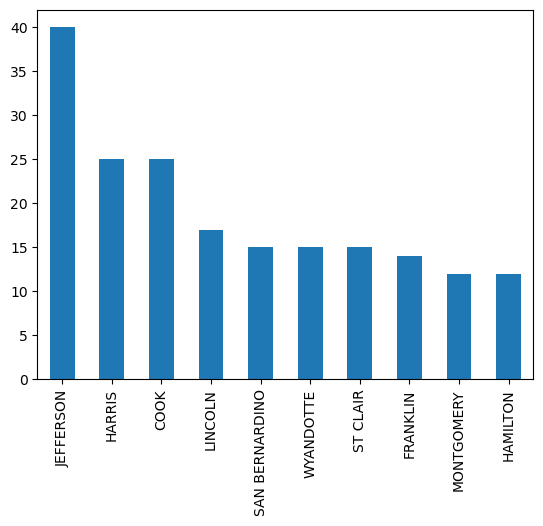

In [13]:
#lets see which county experiences the most accidents
# so basically get a graph x = county, y = number of accidents, all rows in this set are accidents
#get indivial counties and keep track of how many times they appear
import matplotlib.pyplot as plt
counties = Raw_2023_clean['countyname'].value_counts()
#get the top 10 counties
counties = counties[:10,]
print(counties)
counties.plot.bar()
plt.show()


In [10]:
print(Raw_2023_clean.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1043 entries, 102 to 167339
Columns: 132 entries, reportingrailroadcode to specialstudy2
dtypes: object(132)
memory usage: 1.1+ MB
None
